# Homework 3

Collaborators: Edwin Tong, Kevin Shyam Sunder

In [1]:
!mkdir -p ./cpsc375 && wget --quiet --timestamping https://raw.githubusercontent.com/ProfAvery/cpsc375-classwork/refs/heads/main/cpsc375/__init__.py --output-document=./cpsc375/__init__.py

In [2]:
from cpsc375 import *

In [3]:
!pip install lets-plot

# Question 1

Body fat percentage refers to the relative proportions of body weight in terms of lean body mass (muscle, bone, internal organs, and connective tissue) and body fat.

You probably already know that body fat percentage is an important indicator of overall health - too little or too much body fat is associated with several health issues. This assignment is about estimating body fat percentage from other body measurements.

**a.** Why is there a need to estimate body fat percentage instead of directly measuring it? After all, we can directly measure a person’s weight; we don’t need to calculate it. Do an internet search and answer in 2-3 sentences.

**Estimating is better since it is better at measuring for large populations, as it is harder to measure the exact fat percentage of a person. Also, estimations provide faster and affordable results.**

**b.** The bodyfat.csv file in Canvas under Homework 3 contains 13 measurements from subjects (all men) along with their body fat percentage. Read in the file using pd.read_csv().

In [4]:
import pandas as pd
df = pd.read_csv('/content/bodyfat.csv')
df


,Density,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,1.0708,12.3,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,1.0853,6.1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,1.0414,25.3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,1.0751,10.4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,1.0340,28.7,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,1.0736,11.0,70,134.25,67.00,34.9,89.2,83.6,88.8,49.6,34.8,21.5,25.6,25.7,18.5
248,1.0236,33.6,72,201.00,69.75,40.9,108.5,105.0,104.5,59.6,40.8,23.2,35.2,28.6,20.1
249,1.0328,29.3,72,186.75,66.00,38.9,111.1,111.5,101.7,60.3,37.3,21.5,31.3,27.2,18.0
250,1.0399,26.0,72,190.75,70.50,38.9,108.3,101.3,97.8,56.0,41.6,22.7,30.5,29.4,19.8


i. Plot BodyFat vs. Height (show the code, and show the plot)

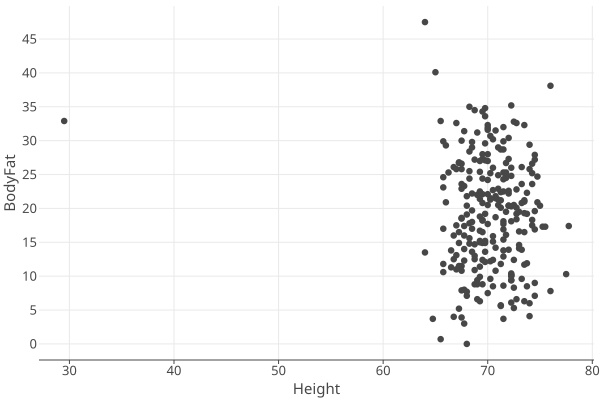

In [5]:
(
    ggplot(pd.read_csv("bodyfat.csv"))
    + geom_point(mapping=aes(x="Height", y="BodyFat"))
    + labs(x="Height", y="BodyFat")
)

ii. Which should be the dependent variable?

**The dependent variable would be BodyFat.**

iii. Which should be the independent variable?

**The independent variable would be Height.**

**c.** There is one obvious outlier in the Height column. Remove the corresponding row from the data and plot again. This will be the data used for the following questions. Confirm that the mean Height is now 70.31076.

i. Show the code to remove the row, plot, and calculate the mean

In [6]:
df = pd.read_csv('bodyfat.csv')

print("Before cleaning:")
print(df['Height'].describe())

df_clean = df[df['Height'] > 40]

mean_height = df_clean['Height'].mean()
print(f"\nNew Mean Height: {mean_height:.5f}")

Before cleaning:
count    252.000000
mean      70.148810
std        3.662856
min       29.500000
25%       68.250000
50%       70.000000
75%       72.250000
max       77.750000
Name: Height, dtype: float64

New Mean Height: 70.31076


ii. Show the plot.

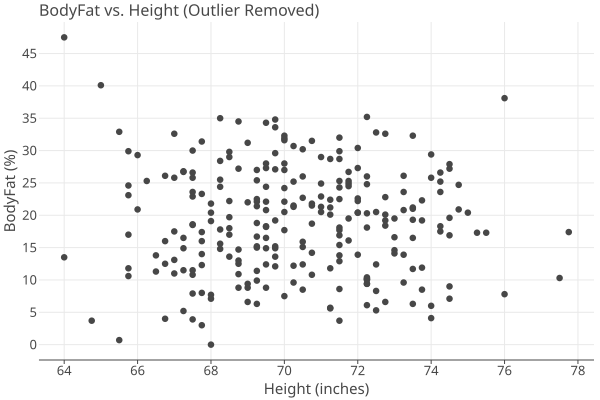

In [7]:
(
    ggplot(df_clean)
    + geom_point(mapping=aes(x="Height", y="BodyFat"))
    + labs(title="BodyFat vs. Height (Outlier Removed)", x="Height (inches)", y="BodyFat (%)")
)

**d.** Use scikit-learn to create a linear model of BodyFat vs. Height.

i. Show LinearRegression() code, and the intercept and coefficient

In [8]:
X = df_clean[['Height']]
y = df_clean['BodyFat']

model = LinearRegression()
model.fit(X, y)

print(f"Intercept: {model.intercept_:.5f}")
print(f"Coefficient (Slope): {model.coef_[0]:.5f}")

Intercept: 24.34120
Coefficient (Slope): -0.07460


ii. What is the R^2 value?

In [9]:
r2_score = model.score(X, y)
print(f"R^2 Value: {r2_score:.5f}")

R^2 Value: 0.00055


iii. Is this a “good” model? Why or why not?

**This isn't a good model. The value of $R^2$ is 0.00055 which is extremely low. There is also no linear relationship between height and body fat percentage.**

iv. What is the linear equation relating BodyFat and Height according to this model?

**BodyFat = 24.34120 - 0.07460 * Height**

**e.** Use statsmodels to create a linear model of BodyFat vs. Weight

i. Show the sm.formula.ols() code and the output of results.summary().

In [10]:
sm.formula.ols("BodyFat ~ Weight", data=df_clean).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                BodyFat   R-squared:                       0.373
Model:                            OLS   Adj. R-squared:                  0.371
Method:                 Least Squares   F-statistic:                     148.2
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           4.60e-27
Time:                        04:46:46   Log-Likelihood:                -829.43
No. Observations:                 251   AIC:                             1663.
Df Residuals:                     249   BIC:                             1670.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -11.8889      2.579     -4.610      0.000     -16.969      -6.809
Weight         0.1733      0.014     12.174      0.000       0.145       0.201
==============================================================================
Omnibus:                        0.065   Durbin-Watson:                   1.610
Prob(Omnibus):                  0.968   Jarque-Bera (JB):                0.109
Skew:                           0.038   Prob(JB):                        0.947
Kurtosis:                       2.933   Cond. No.                     1.12e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.12e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

ii. What is the R^2 value?

**the $R^2$ value is 0.373**

iii. Is this a better model than that based on Height? Why or why not?

**This is a better model since the R^2 value is based on the Weight. This helps with predicting body fat percentage compared to Height.**

iv. What is the linear equation relating BodyFat and Weight according to this model?

**BodyFat = -11.8889 + 0.1733 * Weight**

v. Plot BodyFat vs. Weight and overlay the best fit line. Use a different color for the line.

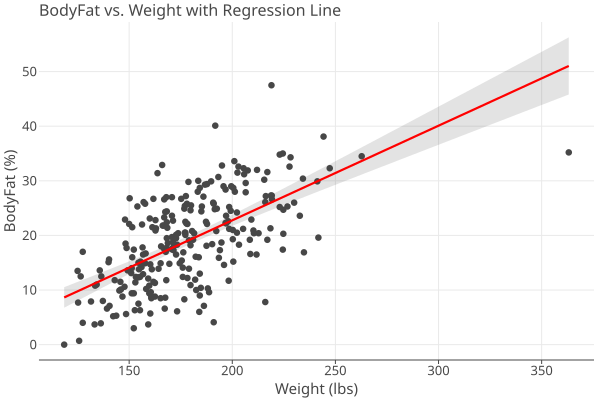

In [11]:
(
    ggplot(df_clean, aes(x="Weight", y="BodyFat"))
    + geom_point()
    + geom_smooth(method="lm", color="red", size=1)
    + labs(title="BodyFat vs. Weight with Regression Line", x="Weight (lbs)", y="BodyFat (%)")
)

vi. From the model, predict the BodyFat for two persons: Person A weighs 150 lbs, Person B weighs 300 lbs. Include the 99% confidence intervals for the predictions. In which prediction (for Person A or B), are you more confident? Why?

In [12]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

weight_model = smf.ols("BodyFat ~ Weight", data=df_clean).fit()

new_data = pd.DataFrame({"Weight": [150, 300]})

predictions = weight_model.get_prediction(new_data)
summary_frame = predictions.summary_frame(alpha=0.01)

summary_frame['Person'] = ['Person A (150 lbs)', 'Person B (300 lbs)']
display(summary_frame[['Person', 'mean', 'obs_ci_lower', 'obs_ci_upper']])

,Person,mean,obs_ci_lower,obs_ci_upper
0,Person A (150 lbs),14.102173,-3.139442,31.343789
1,Person B (300 lbs),40.093254,22.311747,57.874761


**f.** Create a linear model of BodyFat vs. Weight and Height

i. Show the sm.formula.ols() code and the output of results.summary().

In [13]:
sm.formula.ols("BodyFat ~ Weight + Height", data=df_clean).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                BodyFat   R-squared:                       0.509
Model:                            OLS   Adj. R-squared:                  0.505
Method:                 Least Squares   F-statistic:                     128.7
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           4.50e-39
Time:                        04:46:46   Log-Likelihood:                -798.68
No. Observations:                 251   AIC:                             1603.
Df Residuals:                     248   BIC:                             1614.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     72.5244     10.426      6.956      0.000      51.990      93.059
Weight         0.2319      0.014     16.037      0.000       0.203       0.260
Height        -1.3498      0.163     -8.299      0.000      -1.670      -1.029
==============================================================================
Omnibus:                        3.956   Durbin-Watson:                   1.667
Prob(Omnibus):                  0.138   Jarque-Bera (JB):                3.595
Skew:                          -0.262   Prob(JB):                        0.166
Kurtosis:                       3.263   Cond. No.                     5.47e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 5.47e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

ii. What is the R^2 value?

**The $R^2$ value is 0.509**

iii. Is this a better model than that based only on Weight or Height? Why or why not?

**This is a better model since the $R^2$ value is higher as 0.509, equating to around 50.9% of the variance is explained using both Weight and Height together.**

iv. What is the linear equation relating BodyFat, Weight, and Height according to this model?

**72.5244 + 0.2319 * Weight - 1.3498 * Height**

v. From the model, predict the BodyFat for two persons: Person A weighs 150 lbs, Person B weighs 300 lbs. Both persons have height=70”. Include the 99% confidence intervals for the predictions. In which prediction (for Person A or B), are you more confident? Why?

In [14]:
import pandas as pd
import statsmodels.formula.api as smf

multi_model = smf.ols("BodyFat ~ Weight + Height", data=df_clean).fit()

new_data_multi = pd.DataFrame({
    "Weight": [150, 300],
    "Height": [70, 70]
})

pred_results = multi_model.get_prediction(new_data_multi)
pred_summary = pred_results.summary_frame(alpha=0.01)

pred_summary['Person'] = ['Person A (150 lbs, 70")', 'Person B (300 lbs, 70")']
display(pred_summary[['Person', 'mean', 'obs_ci_lower', 'obs_ci_upper']])

,Person,mean,obs_ci_lower,obs_ci_upper
0,"Person A (150 lbs, 70"")",12.830683,-2.459063,28.120429
1,"Person B (300 lbs, 70"")",47.622514,31.684361,63.560667


**There is more confidence for Person A is much closer to the center of the sample data compared to Person B.**

**g.** Add a new transformed variable BMI = Weight/Height2 to the dataset. Create a linear model of BodyFat vs. BMI.

i. Give the sm.formula.ols() code and the output of results.summary()

In [15]:
import statsmodels.formula.api as smf

df_clean = df_clean.assign(BMI=df_clean['Weight'] / (df_clean['Height'] ** 2))

bmi_model = smf.ols("BodyFat ~ BMI", data=df_clean).fit()

display(bmi_model.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                BodyFat   R-squared:                       0.525
Model:                            OLS   Adj. R-squared:                  0.524
Method:                 Least Squares   F-statistic:                     275.7
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           3.44e-42
Time:                        04:46:46   Log-Likelihood:                -794.49
No. Observations:                 251   AIC:                             1593.
Df Residuals:                     249   BIC:                             1600.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -22.8594      2.553     -8.955      0.000     -27.887     -17.832
BMI         1161.9732     69.977     16.605      0.000    1024.152    1299.795
==============================================================================
Omnibus:                        2.558   Durbin-Watson:                   1.672
Prob(Omnibus):                  0.278   Jarque-Bera (JB):                2.285
Skew:                          -0.226   Prob(JB):                        0.319
Kurtosis:                       3.115   Cond. No.                         193.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

ii. Is this a better model than the previous models? Why or why not?

**It is not as good as the weight + height model since the previous model explains more variance.**

iii. What is the equation relating BodyFat, Weight, and Height according to this model? Is this a linear or nonlinear equation?

$BodyFat = -26.3475 + 1184.4533 * (Weight/Height) ^2$

**The equation is nonlinear with respect to the Height variable since is is squared and the denominator.**

iv. Plot BodyFat vs. BMI and overlay the best fit model as a straight line.

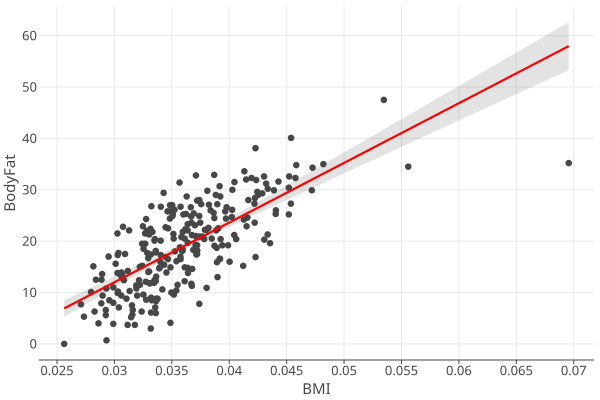

In [16]:
(
    ggplot(df_clean, aes(x="BMI", y="BodyFat"))
    + geom_point()
    + geom_smooth(method="lm", color="red", size=1)
)

v. From the model, predict the BodyFat for two persons: Person A weighs 150 lbs, Person B weighs 300 lbs. Both persons have height=70”. Include the 99% confidence intervals for the predictions.

In [17]:
import pandas as pd
import statsmodels.formula.api as smf

bmi_a = 150 / (70 ** 2)
bmi_b = 300 / (70 ** 2)

new_data_bmi = pd.DataFrame({
    "BMI": [bmi_a, bmi_b]
})

bmi_pred_results = bmi_model.get_prediction(new_data_bmi)
bmi_pred_summary = bmi_pred_results.summary_frame(alpha=0.01)

bmi_pred_summary['Person'] = ['Person A (150 lbs, 70")', 'Person B (300 lbs, 70")']
display(bmi_pred_summary[['Person', 'mean', 'obs_ci_lower', 'obs_ci_upper']])

,Person,mean,obs_ci_lower,obs_ci_upper
0,"Person A (150 lbs, 70"")",12.711243,-2.294409,27.716896
1,"Person B (300 lbs, 70"")",48.281853,32.629751,63.933955


vi. Body Mass Index (BMI) is actually defined as a person’s weight in kilograms divided by the square of height in meters but your data has Weight in pounds and Height in inches. Thus, the correct BMI transformation should have been BMI = (Weight / 2.20) / (Height * 0.0254)2. Would using this correct BMI transformation result in a different model from what was calculated? Why or why not?

**Using the correct metric BMI transformation would not result in a different model in terms of its fit or predictions.**

**($Weight / 2.20$) and inches to meters ($Height * 0.0254$) scaling are linear transformations.**

**h.** Add a new categorical variable AgeGroup to the dataset. AgeGroup should have three values: "Young" for Age ≤ 40, "Middle" for Age between 40 and 60, and "Older" for Age > 60.

i. Show Pandas code that adds the AgeGroup variable. This can be done with assign and the cut() function like so: pd.cut(bodyfat.Age, bins=[-np.inf, 40, 60, np.inf], labels=["Young", "Middle", "Older"])

In [18]:
(
    df_clean
    .assign(AgeGroup=pd.cut(df_clean.Age, bins=[-np.inf, 40, 60, np.inf], labels=["Young", "Middle", "Older"]))
)

,Density,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist,BMI,AgeGroup
0,1.0708,12.3,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1,0.033605,Young
1,1.0853,6.1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2,0.033189,Young
2,1.0414,25.3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6,0.035087,Young
3,1.0751,10.4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2,0.035392,Young
4,1.0340,28.7,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7,0.036294,Young
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,1.0736,11.0,70,134.25,67.00,34.9,89.2,83.6,88.8,49.6,34.8,21.5,25.6,25.7,18.5,0.029906,Older
248,1.0236,33.6,72,201.00,69.75,40.9,108.5,105.0,104.5,59.6,40.8,23.2,35.2,28.6,20.1,0.041315,Older
249,1.0328,29.3,72,186.75,66.00,38.9,111.1,111.5,101.7,60.3,37.3,21.5,31.3,27.2,18.0,0.042872,Older
250,1.0399,26.0,72,190.75,70.50,38.9,108.3,101.3,97.8,56.0,41.6,22.7,30.5,29.4,19.8,0.038378,Older


ii. Create a linear model of BodyFat vs. BMI and AgeGroup.Give the sm.formula.ols() code and the output of results.summary()

In [19]:
df_clean = df_clean.assign(AgeGroup=pd.cut(df_clean.Age, bins=[-np.inf, 40, 60, np.inf], labels=["Young", "Middle", "Older"]))

age_bmi_model = sm.formula.ols("BodyFat ~ BMI + AgeGroup", data=df_clean).fit()

display(age_bmi_model.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                BodyFat   R-squared:                       0.570
Model:                            OLS   Adj. R-squared:                  0.565
Method:                 Least Squares   F-statistic:                     109.2
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           5.09e-45
Time:                        04:46:46   Log-Likelihood:                -782.11
No. Observations:                 251   AIC:                             1572.
Df Residuals:                     247   BIC:                             1586.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            -22.8344      2.455     -9.301      0.000     -27.670     -17.999
AgeGroup[T.Middle]     2.6113      0.761      3.433      0.001       1.113       4.110
AgeGroup[T.Older]      5.3074      1.108      4.792      0.000       3.126       7.489
BMI                 1105.0576     67.831     16.291      0.000     971.456    1238.659
==============================================================================
Omnibus:                        0.954   Durbin-Watson:                   1.839
Prob(Omnibus):                  0.621   Jarque-Bera (JB):                0.869
Skew:                          -0.144   Prob(JB):                        0.648
Kurtosis:                       2.998   Cond. No.                         224.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

iii. How many dummy (i.e., 0-1) variables were created in the model?

**Two dummy variables were created in the model.**

v. What are the set of equations relating BodyFat, BMI, and AgeGroup according to this model?

### Young (>40)
$BodyFat = -29.07 + 1184.22 * BMI$

### Middle (40 - 60)
$BodyFat = (-29.07 + 1.05) + 1184.22 * BMI$

### Older (> 60)
$BodyFat = (-29.07 + 3.16) + 1184.22 * BMI$

vi. Plot BodyFat vs. BMI and overlay the model predictions (Hint: add a new column with predictions and plot the predictions using geom_line. You should see multiple lines, one for each value of the discrete variable).

In [20]:
(
    ggplot(df_clean, aes(x="BMI", y="BodyFat"))
    + geom_point(aes(color="AgeGroup"), alpha=0.6)
    + geom_line(aes(y="Predictions", color="AgeGroup"), size=1)
    + labs(
        title="BodyFat vs. BMI with AgeGroup Model Predictions",
        x="BMI (Imperial)",
        y="BodyFat (%)"
    )
)

# Question 2

Consider the toy dataset below, which shows if 4 subjects have diabetes or not, along with two diagnostic measurements. (Note: do NOT write any code for this problem. The answers are to be computed by hand.)

| Preg | Glucose | HasDiabetes| Preg.Norm | Glucose.Norm |
|------|---------|------------|-----------|--------------|
| 2 | 157 | No | $\frac{2-1}{2} = 0.5$ | $\frac{157-77}{97} \approx 0.825$ |
| 3 | 174 | Yes | $\frac{3-1}{2} = 1.0$ | $\frac{174-77}{97} = 1.000$ |
| 2 | 105 | Yes | $\frac{2-1}{2} = 0.5$ | $\frac{105-77}{97} \approx 0.289$ |
| 1 | 77 | No | $\frac{1-1}{2} = 0.0$ | $\frac{77-77}{97} = 0.000$ |
| 2 | 94 | ? | $\frac{2-1}{2} = 0.5$ | $\frac{94-77}{97} \approx 0.175$ |

**a.** Which variable is the “Class” variable?

**The "Class" variable is HasDiabetes.**

**b.** Normalize the Preg and Glucose values by scaling the minimum-maximum range of each column to 0-1. Fill in the empty columns in the table.

* **Preg**: $[2, 3, 2, 1, 2]$  
  * $\min(\text{Preg}) = 1$
  * $\max(\text{Preg}) = 3$
  * $\text{Denominator} = 3 - 1 = 2$

* **Glucose**: $[157, 174, 105, 77, 94]$  
  * $\min(\text{Glucose}) = 77$
  * $\max(\text{Glucose}) = 174$
  * $\text{Denominator} = 174 - 77 = 97$

**c.** Predict whether a subject with Preg=2, Glucose=94 will have diabetes using the 1-NN algorithm using

(For each of these cases, give the nearest distance, nearest neighbor (e.g., “Row 1” or “Row 2”), and prediction.)

i. Euclidean distance on the original variables

  * **Row 1:** $\sqrt{(2-2)^2 + (157-94)^2} = 63.00$
  * **Row 2:** $\sqrt{(3-2)^2 + (174-94)^2} \approx 80.01$
  * **Row 3:** $\sqrt{(2-2)^2 + (105-94)^2} = 11.00$
  * **Row 4:** $\sqrt{(1-2)^2 + (77-94)^2} \approx 17.03$

ii. Euclidean distance on the normalized variables

In [21]:
import numpy as np
import pandas as pd
from scipy.spatial import distance

norm_data = pd.DataFrame({
    'Preg.Norm': [0.5, 1.0, 0.5, 0.0],
    'Glucose.Norm': [80/97, 97/97, 28/97, 0.0],
    'HasDiabetes': ['No', 'Yes', 'Yes', 'No']
}, index=['Row 1', 'Row 2', 'Row 3', 'Row 4'])

query_norm = np.array([0.5, 17/97])

for label, row in norm_data.iterrows():
    features = np.array([row['Preg.Norm'], row['Glucose.Norm']])
    dist = distance.euclidean(features, query_norm)
    print(f"{label}: Distance = {dist:.4f} (Class: {row['HasDiabetes']})")

Row 1: Distance = 0.6495 (Class: No)
Row 2: Distance = 0.9645 (Class: Yes)
Row 3: Distance = 0.1134 (Class: Yes)
Row 4: Distance = 0.5298 (Class: No)


# Question 3

The pima-indians-diabetes-resampled.csv file on GitHub contains records indicating whether the subjects have diabetes or not, along with certain diagnostic measurements. All subjects are of Pima Indian heritage and this dataset is called the Pima Indian Diabetes Database. The goal is to see if it is possible to predict if a subject has diabetes given some of the diagnostic measurements. (Note: this problem is an extension of the classwork assignment; some additional Python code is also posted on Canvas.)

**a.** Write code to read the data file.

In [24]:
df = pd.read_csv("pima-indians-diabetes-resampled.csv")
df

,Preg,Glucose,BP,Skin,Insulin,BMI,Pedigree,Age,HasDiabetes
0,2,157,74,35,440,39.4,0.134,30,0
1,7,159,64,0,0,27.4,0.294,40,0
2,7,83,78,26,71,29.3,0.767,36,0
3,0,124,56,13,105,21.8,0.452,21,0
4,5,99,54,28,83,34.0,0.499,30,0
...,...,...,...,...,...,...,...,...,...
763,7,81,78,40,48,46.7,0.261,42,0
764,6,125,78,31,0,27.6,0.565,49,1
765,3,130,78,23,79,28.4,0.323,34,1
766,1,116,78,29,180,36.1,0.496,25,0


**b.** What does Preg represent in the dataset? (2-3 sentences. Search for the Pima Indian Diabetes Database online and read up on its background.)

Preg is the number of times the person has been pregnant. the majority is 0 follow by 1, 2, and 3

**c.** 0 values in the Glucose column indicate missing values. Write code to remove rows which contain missing values in that column. You should have 763 rows.

In [25]:
df = df[df['Glucose'] != 0]
df

,Preg,Glucose,BP,Skin,Insulin,BMI,Pedigree,Age,HasDiabetes
0,2,157,74,35,440,39.4,0.134,30,0
1,7,159,64,0,0,27.4,0.294,40,0
2,7,83,78,26,71,29.3,0.767,36,0
3,0,124,56,13,105,21.8,0.452,21,0
4,5,99,54,28,83,34.0,0.499,30,0
...,...,...,...,...,...,...,...,...,...
763,7,81,78,40,48,46.7,0.261,42,0
764,6,125,78,31,0,27.6,0.565,49,1
765,3,130,78,23,79,28.4,0.323,34,1
766,1,116,78,29,180,36.1,0.496,25,0


**d.** Write code to create three new columns/variables which are the normalized versions of Preg, Pedigree, and Glucose columns, scaling the minimum-maximum range of each column to 0-1 (you can use the code posted to Canvas).

In [26]:
df['Preg_norm'] = (df['Preg'] - df['Preg'].min()) / (df['Preg'].max() - df['Preg'].min())

df['Pedigree_norm'] = (df['Pedigree'] - df['Pedigree'].min()) / (df['Pedigree'].max() - df['Pedigree'].min())

df['Glucose_norm'] = (df['Glucose'] - df['Glucose'].min()) / (df['Glucose'].max() - df['Glucose'].min())

print(df[['Preg_norm', 'Pedigree_norm', 'Glucose_norm']].describe())

        Preg_norm  Pedigree_norm  Glucose_norm
count  763.000000     763.000000    763.000000
mean     0.226582       0.168436      0.501205
std      0.198513       0.141744      0.197004
min      0.000000       0.000000      0.000000
25%      0.058824       0.070666      0.354839
50%      0.176471       0.126388      0.470968
75%      0.352941       0.234202      0.625806
max      1.000000       1.000000      1.000000


/tmp/ipykernel_4617/2261518794.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Preg_norm'] = (df['Preg'] - df['Preg'].min()) / (df['Preg'].max() - df['Preg'].min())
/tmp/ipykernel_4617/2261518794.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Pedigree_norm'] = (df['Pedigree'] - df['Pedigree'].min()) / (df['Pedigree'].max() - df['Pedigree'].min())
/tmp/ipykernel_4617/2261518794.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[ro

**e.** Split the dataset into train and test datasets with the first 500 rows for training, and the remaining rows for test. Do NOT randomly sample the data (though resampling is usually done, this homework problem does not use this step for consistency when grading).

In [28]:
from sklearn.neighbors import KNeighborsClassifier
x_train = df[['Preg','Pedigree']].iloc[:500]
y_train = df['HasDiabetes'].iloc[:500]
x_test = df[['Preg','Pedigree']].iloc[500:]
y_test = df['HasDiabetes'].iloc[500:]
mod = KNeighborsClassifier(n_neighbors=1)
mod.fit(x_train, y_train)
mod.predict(x_test)
mod.score(x_test, y_test) # this number is the percentage of how many you got right

0.596958174904943

**f.** Train and test a k-nearest neighbor classifier with the dataset. Consider only the normalized Preg and Pedigree columns. Set k = 1. What is the error rate (number of misclassifications)?

In [29]:
1 - mod.score(x_test, y_test)


0.40304182509505704

**g.** Repeat part (f) but consider the normalized Preg, Pedigree, and Glucose columns. Set k = 1. What is the error rate? Will the error rate always decrease with a larger number of features? Why or why not? Answer in 2-3 sentences.

In [30]:
x_train = df[['Preg_norm','Pedigree_norm']].iloc[:500]
y_train = df['HasDiabetes'].iloc[:500]
x_test = df[['Preg_norm','Pedigree_norm']].iloc[500:]
y_test = df['HasDiabetes'].iloc[500:]
mod = KNeighborsClassifier(n_neighbors=1)
mod.fit(x_train, y_train)
mod.predict(x_test)
1- mod.score(x_test, y_test)

0.40684410646387836

no it does not look like the score decrease. additional features by be noisy or not work at all which can make it less accurate and could even increase error rate.


**h.** Repeat part (g) but set k = 5. What is the error rate?

In [31]:
mod = KNeighborsClassifier(n_neighbors=5)
mod.fit(x_train, y_train)
mod.predict(x_test)
1- mod.score(x_test, y_test)

0.42205323193916355

**i.** Repeat part (h) but set k = 11. What is the error rate?

In [32]:
mod = KNeighborsClassifier(n_neighbors=11)
mod.fit(x_train, y_train)
mod.predict(x_test)
1- mod.score(x_test, y_test)

0.3269961977186312

**j.** Considering your observations from (g) - (i), which is the best value for k?

The best value for k in this case is 11 since it has the lowest error rate


#Question 4

What would the 1-Nearest Neighbor approach predict is the class when the feature set is { Soymilk, Apple, Eggs } and the following data is used as the training data? (This is the same table as the classwork.) Use the Jaccard similarity to calculate neighbors. Show your calculations. (Note: do NOT write any code for this problem. The answers are to be computed by hand.)


|     | Feature Set  | Class    |
|-----|--------------|----------|
| A  | { Apple, Banana, Soymilk, Yogurt } | Vegetarian |
| B  | { Apple, Peanuts, Yogurt } | Vegetarian |
| C  | { Tomatoes, Potatoes, Yogurt } | Non-Vegetarian |
| D  | { Apple, Tomatoes, Potatoes } | Non-Vegetarian |

$$J(Q, T) = \frac{|Q \cap T|}{|Q \cup T|}$$


$$Q = \{\text{Soymilk}, \text{Apple}, \text{Eggs}\}$$  
Size $|Q| = 3$.

#### 1. $T_A = \{\text{Apple}, \text{Banana}, \text{Soymilk}, \text{Yogurt}\}$
(Class: Vegetarian)
* **Intersection ($Q \cap T_A$):** $\{\text{Soymilk}, \text{Apple}\}$ $=>$ size $= 2$
* **Union ($Q \cup T_A$):** $\{\text{Soymilk}, \text{Apple}, \text{Eggs}, \text{Banana}, \text{Yogurt}\}$ $=>$ size $= 5$
* **Similarity $J(Q, T_A)$:** $\frac{2}{5} = 0.40$

#### 2. $T_B = \{\text{Apple}, \text{Peanuts}, \text{Yogurt}\}$ (Class: Vegetarian)
* **Intersection ($Q \cap T_B$):** $\{\text{Apple}\}$ $=>$ size $= 1$
* **Union ($Q \cup T_B$):** $\{\text{Soymilk}, \text{Apple}, \text{Eggs}, \text{Peanuts}, \text{Yogurt}\}$ $=>$ size $= 5$
* **Similarity $J(Q, T_B)$:** $\frac{1}{5} = 0.20$

#### 3. $T_C = \{\text{Tomatoes}, \text{Potatoes}, \text{Yogurt}\}$ (Class: Non-Vegetarian)
* **($Q \cap T_C$):** $empty set$ $=>$ size $= 0$
* **($Q \cup T_C$):** $\{\text{Soymilk}, \text{Apple}, \text{Eggs}, \text{Tomatoes}, \text{Potatoes}, \text{Yogurt}\}$ $=>$ size $= 6$
* **$J(Q, T_C)$:** $\frac{0}{6} = 0.00$

#### 4. $T_D = \{\text{Apple}, \text{Tomatoes}, \text{Potatoes}\}$ (Class: Non-Vegetarian)
* **Intersection ($Q \cap T_D$):** $\{\text{Apple}\}$ $=>$ size $= 1$
* **Union ($Q \cup T_D$):** $\{\text{Soymilk}, \text{Apple}, \text{Eggs}, \text{Tomatoes}, \text{Potatoes}\}$ $=>$ size $= 5$
* **Similarity $J(Q, T_D)$:** $\frac{1}{5} = 0.20$

### Conclusion:
* **Nearest Neighbor:** **Instance A**
* **Predicted Class:** **Vegetarian**

# Question 5

Consider the following dataset. (Note: do NOT write any code for this problem. The answers are to be computed by hand and marked on the graph. You can visually guess some of the answers.)

| Length | 120 | 140 | 130 | 170 | 160 | 180 |
|--------|-----|-----|-----|-----|-----|-----|
| Width  | 60  | 70 | 80 | 40 | 30  | 20 |

**a.** Mark the data points on the graph below (use ‘+’ to indicate each point).

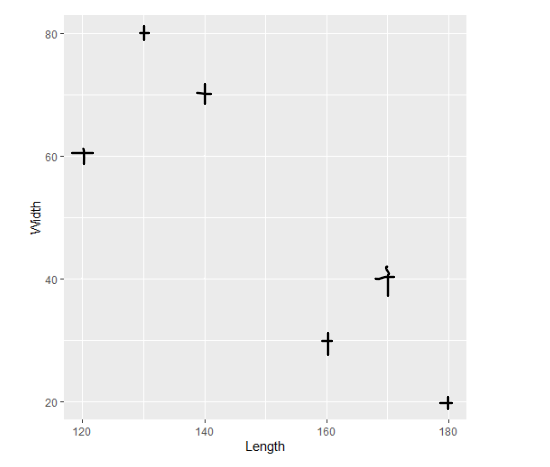

**b.** Let k = 2. Let one of the two initial centers be (Length = 120, Width = 60). Select the second center using the Farthest Distance Heuristic. Indicate the two centers on the graph (circle the centers).

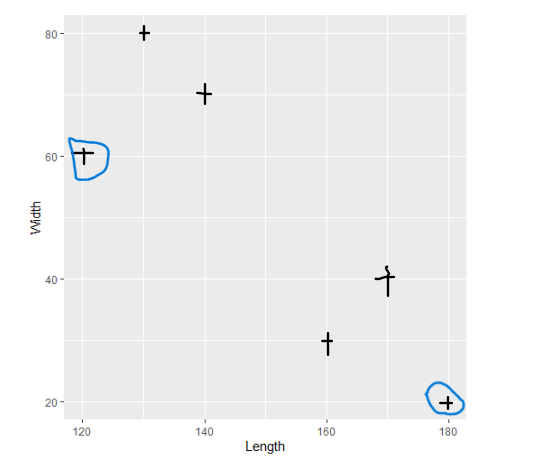

**c.** Recompute the centers after the first iteration of the k-means algorithm.

(Indicate the two new centers on the graph (mark new centers with squares).)

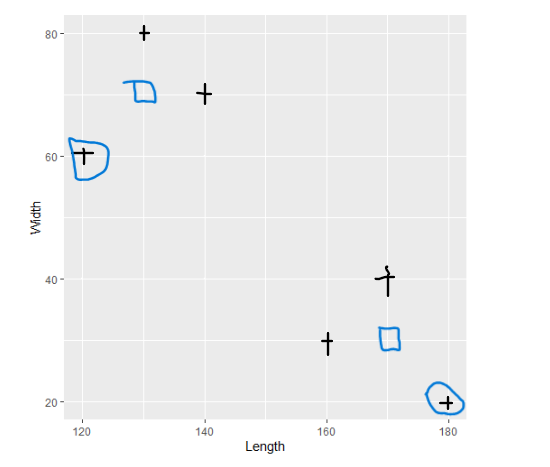

New center 1: length 130 width 70

New center 2: length 170 width 30

**d.** What are the two clusters after this first iteration? Draw two ovals, each containing all the points in one cluster in the graph above.

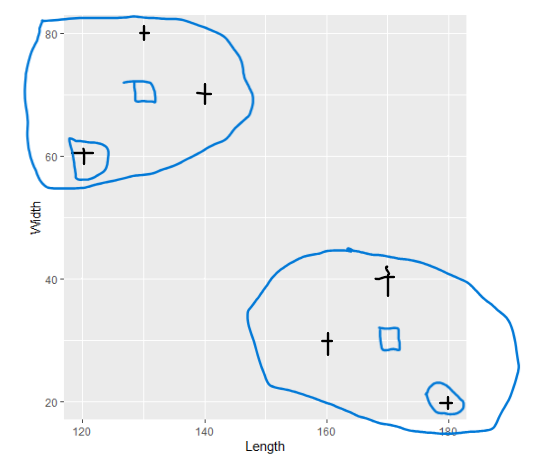

**e.** Will the k-means algorithm terminate after this first iteration or will it continue? Answer in 1-2 sentences.

Yes it will terminate as it did not get any new points after the first iteration. This mean the center will not move.

**f.** If a new point (Length = 140, Width = 60) is added, to which cluster will it belong?

I think it will belong to the first cluster on the top left. The center will be move

New Center: length 132.5 width 67.5